# VoiceSnake — Train GRU từ đầu, 4 hướng

Huấn luyện **từ trọng số ngẫu nhiên**, đúng thứ tự lớp `up, right, left, down`. Dùng PyTorch GRU hai chiều; không tải pretrained weights. Đầu vào triển khai vẫn là waveform mono float32 **16 kHz, 16.000 samples**. STFT và chuẩn hóa được đóng gói trong model export, không dùng preprocessing của checkpoint RF5 cũ.

Dữ liệu: [TensorFlow mini Speech Commands](https://www.tensorflow.org/tutorials/audio/simple_audio), 1.000 clip mỗi từ. Chia theo ID người nói, không chia ngẫu nhiên từng clip. Chỉ bốn từ hướng tham gia training; các từ khác chỉ dùng đánh giá ngoài phân phối trên nhóm người nói test.

**Lưu ý:** Bỏ các output từ khác không tạo khả năng từ chối các từ đó. Softmax 4 lớp luôn phân bố xác suất vào 4 hướng; vẫn cần energy gate, confidence và kiểm tra microphone khi tích hợp. Không khẳng định model mới tốt hơn trước khi đo.

In [1]:
import os, sys, json, time, random, hashlib, zipfile, shutil, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Audio

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASSES = ['up', 'right', 'left', 'down']  # DO NOT sort this list during inference
SR, SAMPLES = 16000, 16000
BATCH_SIZE, EPOCHS, PATIENCE = 64, 35, 8
LEARNING_RATE = 0.001
OUT = Path('training_outputs/voicesnake_gru4'); OUT.mkdir(parents=True, exist_ok=True)
DATA = Path('data/mini_speech_commands')
print('Python:', sys.version.split()[0], '| torch:', torch.__version__, '| device:', DEVICE)
print('Classes:', dict(enumerate(CLASSES)), '| threads:', torch.get_num_threads())

Matplotlib is building the font cache; this may take a moment.


Python: 3.9.6 | torch: 2.8.0 | device: cpu
Classes: {0: 'up', 1: 'right', 2: 'left', 3: 'down'} | threads: 4


## 1. Tải và chia dữ liệu theo người nói

Notebook tự tải archive (~174 MiB); nếu archive đã có trong thư mục data thì dùng lại. Mỗi ID trước `_nohash_` chỉ thuộc một tập. SHA-1 của speaker ID xác định split 70/15/15 xấp xỉ; tỷ lệ số clip thực tế được in phía dưới. Test không tham gia lựa chọn checkpoint.

In [2]:
if not all((DATA / label).is_dir() for label in CLASSES):
    DATA.parent.mkdir(parents=True, exist_ok=True)
    archive = DATA.parent / 'mini_speech_commands.zip'
    if not archive.exists():
        urllib.request.urlretrieve('https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip', archive)
    with zipfile.ZipFile(archive) as z:
        root = DATA.parent.resolve()
        for info in z.infolist():
            dest = (root / info.filename).resolve()
            if root != dest and root not in dest.parents:
                raise ValueError('Unsafe archive member')
        z.extractall(root)

def speaker(path):
    return Path(path).stem.split('_nohash_')[0]

def split_for(path):
    bucket = int(hashlib.sha1(speaker(path).encode()).hexdigest(), 16) % 100
    return 'train' if bucket < 70 else ('val' if bucket < 85 else 'test')

rows = []
for index, label in enumerate(CLASSES):
    for path in sorted((DATA / label).glob('*.wav')):
        rows.append(dict(path=str(path), label=label, target=index, speaker=speaker(path), split=split_for(path)))
manifest = pd.DataFrame(rows)
assert len(manifest) > 0
assert manifest.groupby('speaker')['split'].nunique().max() == 1
counts = pd.crosstab(manifest['split'], manifest['label']).reindex(['train', 'val', 'test'])[CLASSES]
assert (counts > 0).all().all(), 'Each split must contain all four classes'
display(counts)
manifest.to_csv(OUT / 'split_manifest.csv', index=False)
print('Speakers:', manifest.groupby('split')['speaker'].nunique().to_dict())

label,up,right,left,down
split,,,,
train,675,689,667,685
val,169,148,172,158
test,156,163,161,157


Speakers: {'test': 235, 'train': 1033, 'val': 235}


## 2. Waveform và log-spectrogram

Mỗi clip zero-pad bên phải hoặc crop còn 1 giây. STFT cửa sổ Hann 25 ms, hop 10 ms; gộp cặp tần số còn 100 bins, lấy log power và chuẩn hóa mean/std trên mỗi clip. Tensor đặc trưng: `(batch, 101 frames, 100 bins)`. Chỉ cache đặc trưng để train CPU nhanh hơn; frontend export dùng đúng phép biến đổi này.

Augmentation chỉ ở tập train: che một vùng thời gian và một vùng tần số nhỏ. Validation/test không augmentation.

In [3]:
def read_audio(path):
    x, sr = sf.read(path, dtype='float32')
    if sr != SR or x.ndim != 1 or not np.isfinite(x).all():
        raise ValueError(f'Expected finite mono 16 kHz WAV: {path}')
    return np.pad(x[:SAMPLES], (0, max(0, SAMPLES-len(x)))).astype(np.float32)

class Frontend(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer('window', torch.hann_window(400))

    def forward(self, waveform):
        spectrum = torch.stft(waveform, n_fft=400, hop_length=160, win_length=400,
                              window=self.window, center=True, return_complex=True)
        power = spectrum.abs().square()[:, :200, :]
        power = power.reshape(power.size(0), 100, 2, power.size(-1)).mean(dim=2)
        features = torch.log(power.clamp_min(1e-6))
        mean = features.mean(dim=(1, 2), keepdim=True)
        std = features.std(dim=(1, 2), keepdim=True).clamp_min(1e-5)
        return ((features-mean)/std).transpose(1, 2)

frontend = Frontend().eval()
features, targets = [], []
with torch.inference_mode():
    for start in range(0, len(manifest), 64):
        part = manifest.iloc[start:start+64]
        audio = torch.from_numpy(np.stack([read_audio(p) for p in part.path]))
        features.append(frontend(audio).clone())
        targets.extend(part.target.tolist())
X, y = torch.cat(features).clone(), torch.tensor(targets, dtype=torch.long)
print('Feature cache:', tuple(X.shape), '| MiB:', X.numel()*4/2**20)
display(Audio(read_audio(manifest.iloc[0].path), rate=SR))

class FeatureDataset(Dataset):
    def __init__(self, indices, augment=False):
        self.indices = list(indices); self.augment = augment
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]; x = X[j].clone()
        if self.augment:
            t = random.randrange(x.shape[0]-6+1); x[t:t+6, :] = 0
            f = random.randrange(x.shape[1]-5+1); x[:, f:f+5] = 0
        return x, y[j]

loaders = {}
for split in ['train', 'val', 'test']:
    indices = manifest.index[manifest.split == split].tolist()
    loaders[split] = DataLoader(FeatureDataset(indices, augment=split=='train'),
                                batch_size=BATCH_SIZE, shuffle=split=='train', num_workers=0)

Feature cache: (4000, 101, 100) | MiB: 154.11376953125


## 3. GRU riêng cho bốn lớp

Một tầng bidirectional GRU, hidden size 64 mỗi chiều. Ghép mean pooling và max pooling trên chuỗi → Linear 64 → 4 logits. Không có CNN hay pretrained backbone. Mô hình bắt đầu ngẫu nhiên; CrossEntropyLoss nhận logits chưa softmax.

In [4]:
class DirectionGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.frontend = Frontend()
        self.gru = nn.GRU(100, 64, num_layers=1, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Linear(256, 64), nn.ReLU(), nn.Dropout(.25), nn.Linear(64, 4))

    def forward_features(self, features):
        sequence, _ = self.gru(features)
        pooled = torch.cat([sequence.mean(dim=1), sequence.max(dim=1).values], dim=1)
        return self.head(pooled)

    def forward(self, waveform):
        return self.forward_features(self.frontend(waveform))

model = DirectionGRU().to(DEVICE)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=.5, patience=3)

DirectionGRU(
  (frontend): Frontend()
  (gru): GRU(100, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Linear(in_features=64, out_features=4, bias=True)
  )
)
Trainable parameters: 80452


## 4. Training từ đầu và early stopping

Lưu checkpoint theo **validation loss** thấp nhất. Dừng sau 8 epoch không cải thiện; tối đa 35 epoch. File progress được ghi sau mỗi epoch để theo dõi khi chạy notebook nền. Không sử dụng test để chọn epoch hay learning rate.

In [5]:
def run_epoch(loader, training):
    model.train(training)
    total_loss, correct, total = 0., 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if training: optimizer.zero_grad(set_to_none=True)
            logits = model.forward_features(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                optimizer.step()
            total_loss += loss.item()*len(yb)
            correct += (logits.argmax(1)==yb).sum().item(); total += len(yb)
    return total_loss/total, correct/total

history, best_loss, stale = [], float('inf'), 0
train_start = time.perf_counter()
for epoch in range(1, EPOCHS+1):
    start = time.perf_counter()
    train_loss, train_acc = run_epoch(loaders['train'], True)
    val_loss, val_acc = run_epoch(loaders['val'], False)
    scheduler.step(val_loss)
    row = dict(epoch=epoch, train_loss=train_loss, train_acc=train_acc,
               val_loss=val_loss, val_acc=val_acc, seconds=time.perf_counter()-start)
    history.append(row)
    pd.DataFrame(history).to_csv(OUT/'history.csv', index=False)
    print(f'Epoch {epoch:02d}: train {train_loss:.4f}/{train_acc:.3%} | val {val_loss:.4f}/{val_acc:.3%} | {row["seconds"]:.1f}s', flush=True)
    if val_loss < best_loss-1e-4:
        best_loss, stale = val_loss, 0
        torch.save({'model_state_dict': {k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
                    'classes': CLASSES, 'sample_rate': SR, 'samples': SAMPLES,
                    'architecture': 'logspec_bigru64_v1', 'epoch': epoch,
                    'val_loss': val_loss, 'seed': SEED}, OUT/'best_state.pt')
    else: stale += 1
    if stale >= PATIENCE:
        print('Early stopping'); break
train_seconds = time.perf_counter()-train_start
best = torch.load(OUT/'best_state.pt', map_location='cpu', weights_only=True)
model.load_state_dict(best['model_state_dict'], strict=True)
model.eval()
print('Best epoch:', best['epoch'], '| training seconds:', round(train_seconds, 1))

Epoch 01: train 1.3150/37.297% | val 1.1870/57.187% | 1.7s


Epoch 02: train 0.9955/63.292% | val 0.7399/79.753% | 1.5s


Epoch 03: train 0.5997/79.971% | val 0.4206/85.781% | 1.6s


Epoch 04: train 0.4114/85.751% | val 0.3635/87.481% | 1.5s


Epoch 05: train 0.3244/88.586% | val 0.3723/86.399% | 1.6s


...

Epoch 23: train 0.0426/98.785% | val 0.2451/93.354% | 1.5s


Epoch 24: train 0.0410/98.785% | val 0.2444/93.509% | 1.5s


Epoch 25: train 0.0397/98.895% | val 0.2422/93.663% | 1.5s


Epoch 26: train 0.0342/98.969% | val 0.2438/93.663% | 1.6s


Early stopping
Best epoch: 18 | training seconds: 40.5


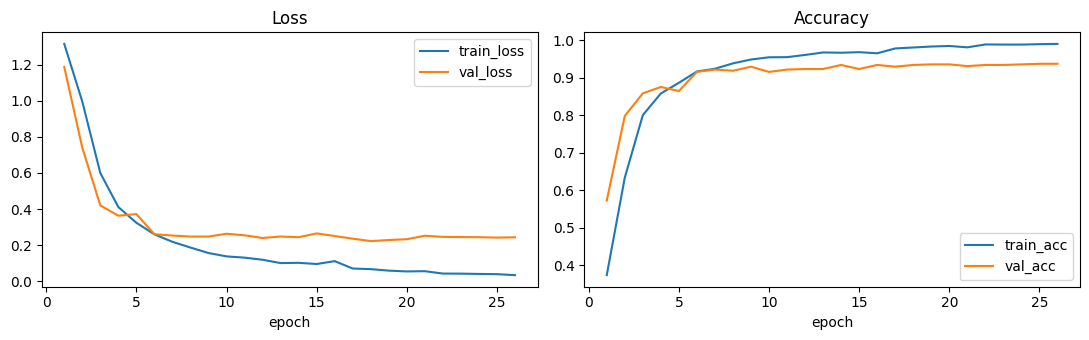

In [6]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
hist.plot(x='epoch', y=['train_loss','val_loss'], ax=axes[0], title='Loss')
hist.plot(x='epoch', y=['train_acc','val_acc'], ax=axes[1], title='Accuracy')
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png', dpi=150); plt.show()

## 5. Đánh giá test độc lập và các từ ngoài bốn lớp

Accuracy, precision/recall/F1 và confusion matrix chỉ trên các clip hướng test. Kiểm tra ngoài phân phối dùng `yes/no/stop/go` từ **speaker test**, không đưa vào training và không thêm output lớp thứ năm. Báo tỷ lệ clip ngoài lệnh vượt threshold và energy gate; đây là clip-level, chưa phải false activations/phút khi chạy liên tục.

              precision    recall  f1-score   support

          up     0.8772    0.9615    0.9174       156
       right     0.9394    0.9509    0.9451       163
        left     0.9608    0.9130    0.9363       161
        down     0.9932    0.9363    0.9639       157

    accuracy                         0.9403       637
   macro avg     0.9427    0.9405    0.9407       637
weighted avg     0.9428    0.9403    0.9407       637



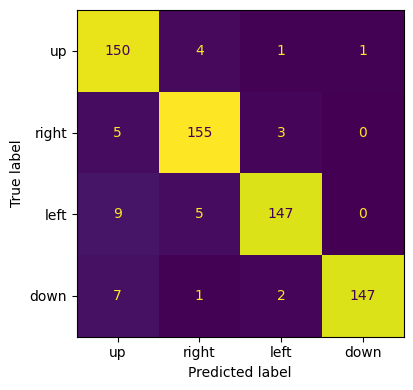

,clips,false_accept_rate
word,,
go,164,0.829268
no,161,0.813665
stop,185,0.735135
yes,180,0.911111


1292

In [7]:
truth, predicted, confidence = [], [], []
with torch.inference_mode():
    for xb, yb in loaders['test']:
        p = model.forward_features(xb.to(DEVICE)).softmax(-1).cpu()
        truth.extend(yb.tolist()); predicted.extend(p.argmax(1).tolist()); confidence.extend(p.max(1).values.tolist())
print(classification_report(truth, predicted, labels=list(range(4)), target_names=CLASSES, digits=4, zero_division=0))
report = classification_report(truth, predicted, labels=list(range(4)), target_names=CLASSES, output_dict=True, zero_division=0)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(truth, predicted, labels=list(range(4))), display_labels=CLASSES).plot(ax=ax, colorbar=False)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrix.png', dpi=150); plt.show()

# Fixed thresholds for inspection. No selection using test results.
CONFIDENCE_THRESHOLD, ENERGY_THRESHOLD = .7, .004
outside = [p for word in ['yes','no','stop','go'] for p in sorted((DATA/word).glob('*.wav')) if split_for(p)=='test']
ood_rows = []
with torch.inference_mode():
    for start in range(0, len(outside), BATCH_SIZE):
        paths = outside[start:start+BATCH_SIZE]
        waveforms = np.stack([read_audio(p) for p in paths])
        probs = model(torch.from_numpy(waveforms).to(DEVICE)).softmax(-1).cpu()
        for i, path in enumerate(paths):
            rms = float(np.sqrt(np.mean(waveforms[i]**2)))
            score = float(probs[i].max())
            ood_rows.append(dict(file=str(path), word=path.parent.name, predicted=CLASSES[int(probs[i].argmax())],
                                 confidence=score, rms=rms, accepted=score>=CONFIDENCE_THRESHOLD and rms>=ENERGY_THRESHOLD))
ood = pd.DataFrame(ood_rows)
if not ood.empty:
    display(ood.groupby('word').agg(clips=('accepted','size'), false_accept_rate=('accepted','mean')))
    ood.to_csv(OUT/'outside_commands.csv', index=False)
summary = dict(classes=CLASSES, best_epoch=best['epoch'], training_seconds=train_seconds,
               test_clips=len(truth), report=report, confidence_threshold=CONFIDENCE_THRESHOLD,
               energy_threshold=ENERGY_THRESHOLD, outside_test_clips=len(ood),
               outside_false_accept_rate=float(ood.accepted.mean()) if len(ood) else None)
(OUT/'metrics.json').write_text(json.dumps(summary, indent=2))

## 6. Export cho inference CPU và benchmark

`voicesnake_gru4.pt` là TorchScript có cả frontend, nhận `(B,16000)` raw waveform, trả `(B,4)` logits theo `labels.json`. Game đóng gói sử dụng chính định dạng TorchScript này. `best_state.pt` dùng để khôi phục trọng số với class `DirectionGRU` ở trên. Model mới có frontend riêng, có đúng bốn đầu ra và được train từ đầu.

Đo batch=1 sau warm-up, bao gồm STFT + GRU + head. Đây là latency model, chưa gồm microphone, xác nhận lệnh hay game tick.

In [8]:
cpu_model = model.cpu().eval()
torch.set_num_threads(min(2, os.cpu_count() or 1))
example = torch.from_numpy(read_audio(manifest[manifest.split=='test'].iloc[0].path)).unsqueeze(0)
with torch.inference_mode():
    exported = torch.jit.trace(cpu_model, example)
    exported.save(str(OUT/'voicesnake_gru4.pt'))
    loaded = torch.jit.load(str(OUT/'voicesnake_gru4.pt'), map_location='cpu').eval()
    for probe in [example, torch.randn(1, SAMPLES)*.05, torch.zeros(1, SAMPLES)]:
        torch.testing.assert_close(loaded(probe), cpu_model(probe), rtol=1e-4, atol=1e-5)
    for _ in range(10): loaded(example)
    durations=[]
    for _ in range(100):
        start=time.perf_counter(); loaded(example); durations.append((time.perf_counter()-start)*1000)
metadata = dict(classes=CLASSES, sample_rate=SR, samples=SAMPLES, input='float32 raw mono waveform [-1,1]',
                output='4 logits; softmax over all four outputs', architecture='logspec_bigru64_v1',
                cpu_threads=torch.get_num_threads(), latency_p50_ms=float(np.median(durations)),
                latency_p95_ms=float(np.percentile(durations,95)))
(OUT/'labels.json').write_text(json.dumps(metadata, indent=2))
print(json.dumps(metadata, indent=2))

{
  "classes": [
    "up",
    "right",
    "left",
    "down"
  ],
  "sample_rate": 16000,
  "samples": 16000,
  "input": "float32 raw mono waveform [-1,1]",
  "output": "4 logits; softmax over all four outputs",
  "architecture": "logspec_bigru64_v1",
  "cpu_threads": 2,
  "latency_p50_ms": 1.852999999996996,
  "latency_p95_ms": 1.9465249999896628
}


## 7. Adapter có cùng output với `Recognizer.predict()` trong game

Code dưới trả `(label, confidence, inference_ms)` đúng giao diện hiện tại. Khi tích hợp, worker dùng adapter cùng giao diện này. Copy cả model `.pt` và `labels.json`; không thay checkpoint RF5 bằng file mới vì hai định dạng khác nhau. Energy gate, confirmation và latch của game tiếp tục thực hiện sau prediction.

In [9]:
class FourClassRecognizer:
    def __init__(self, model_path, labels_path):
        self.metadata = json.loads(Path(labels_path).read_text())
        self.classes = self.metadata['classes']
        assert self.classes == ['up', 'right', 'left', 'down']
        self.network = torch.jit.load(str(model_path), map_location='cpu').eval()
    @torch.inference_mode()
    def predict(self, samples):
        samples = np.asarray(samples, dtype=np.float32)
        if samples.shape != (16000,) or not np.isfinite(samples).all():
            raise ValueError('Expected 16000 finite mono samples at 16 kHz')
        x = torch.from_numpy(samples.copy())[None]
        start = time.perf_counter()
        p = self.network(x)[0].softmax(-1)
        ms = (time.perf_counter()-start)*1000
        return self.classes[int(p.argmax())], float(p.max()), ms

recognizer = FourClassRecognizer(OUT/'voicesnake_gru4.pt', OUT/'labels.json')
print('Example:', recognizer.predict(read_audio(manifest[manifest.split=='test'].iloc[0].path)))
bundle = shutil.make_archive(str(OUT.parent/'voicesnake_gru4_bundle'), 'zip', OUT)
print('Bundle:', bundle)
# Trên Colab: bỏ comment để tải bundle về máy.
# from google.colab import files
# files.download(bundle)

Example: ('up', 0.99934321641922, 3.198582999999644)
Bundle: /Users/nktsagd/dev/speech/training_outputs/voicesnake_gru4_bundle.zip


## Nhận xét kết quả

Đọc accuracy và recall từng hướng, đặc biệt `left`, cùng chênh lệch train/validation. Nếu ngoài lệnh vẫn bị nhận thành hướng với confidence cao, đó là giới hạn của phân loại đóng bốn lớp; giảm số lớp không tự giải quyết false activation. Điều chỉnh ngưỡng bằng validation/thu âm riêng, sau đó đánh giá một tập microphone chưa dùng để điều chỉnh.

Mini Speech Commands là baseline nhỏ. Thêm giọng thực tế và nhiễu nền vào **tập train**, giữ speaker test riêng, trước khi kết luận về khả năng chơi. Việc đo live cần cửa sổ trượt và thời gian tới game tick; clip-level accuracy không thay thế phép đo đó.

Tài liệu: [PyTorch GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html), [nguồn mini Speech Commands](https://www.tensorflow.org/tutorials/audio/simple_audio).

## Kết quả chạy thực tế trên máy này

- CPU, PyTorch 2.8.0; 4 threads training và 2 threads benchmark.
- 4.000 clip, chia người nói riêng; 637 clip test.
- Early stopping sau 26 epoch; chọn checkpoint **epoch 18** bằng validation loss. Thời gian vòng training: **40,50 giây**, không gồm cài dependency, tải/đọc dữ liệu hoặc đánh giá.
- Test accuracy **94,03%**, macro-F1 **0,9407**; recall `left` **91,30%**.
- CPU latency frontend + GRU, batch=1: p50 **1,853 ms**, p95 **1,947 ms**; chưa đo end-to-end microphone.
- Trên 690 clip ngoài hướng (`yes/no/stop/go`), **82,17% vượt confidence 0.7 và RMS 0.004** trong phép kiểm tra toàn clip. Không dùng confirmation/sliding-window của game ở phép đo này. Đây là bằng chứng rằng chỉ bỏ các lớp khác **không ngăn được nhận nhầm từ ngoài hướng**.

Artifact đã xuất trong `training_outputs/voicesnake_gru4/`; tất cả code cell đã chạy và có output. TorchScript đã được nạp lại và đối chiếu output với model PyTorch. Model này được xuất riêng, đã được đóng gói cho game trong `voicesnake/assets/`. Notebook cung cấp adapter có cùng giao diện output để tích hợp.
